# Лабораторная работа №4. Гибридный поиск в Qdrant

Цель работы — собрать поисковую систему, которая одновременно учитывает:

- **смысл текста** с помощью dense-векторов;
- **точные совпадения слов** с помощью sparse-векторов BM25;
- оба сигнала вместе с помощью гибридного поиска.

Вся работа выполнена в одном ноутбуке. В качестве корпуса используется SberQuAD из предыдущей лабораторной, а для семантических векторов — дообученная в лабораторной №3 модель `multilingual-e5-small`.

## 1. Что требуется по заданию

1. Развернуть векторную базу данных. Здесь используется **Qdrant в локальном режиме**: база запускается прямо внутри Python-процесса и предоставляет тот же API коллекций, dense- и sparse-векторов, но не требует Docker.
2. Выбрать датасет и создать коллекцию документов. Используем SberQuAD: вопрос является запросом, связанный с ним контекст — релевантным документом.
3. Построить два представления документов:
   - семантическое — моделью E5;
   - лексическое — BM25.
4. Загрузить оба вектора и текст документа в Qdrant.
5. Подобрать размер пула кандидатов с учётом качества и времени поиска.
6. Проверить гибридный поиск для `alpha` от 0 до 1 с шагом 0.1.

На каждом запросе известен один релевантный документ. Поэтому качество можно измерить по позиции этого документа в выдаче.

## 2. Теория простыми словами

### Векторная база

Обычная база хорошо ищет по точному условию: например, `id = 10`. Векторная база хранит числовые представления объектов и умеет быстро находить ближайшие. В этой работе одна точка Qdrant соответствует одному документу и содержит:

- `dense` — обычный плотный вектор смысла;
- `lexical` — разреженный вектор BM25;
- `payload` — исходный текст и идентификатор документа.

### Семантический, или dense-поиск

Нейросеть превращает запрос и документ в векторы одинаковой длины. Близость нормированных векторов измеряется косинусным сходством. Такой поиск способен сопоставить разные формулировки одной мысли, но иногда пропускает важное точное слово, имя или число.

E5 ожидает префиксы `query:` для запроса и `passage:` для документа. Они сообщают модели, какую роль выполняет текст.

### Лексический, или sparse-поиск

BM25 работает со словами. Важность слова увеличивается, если оно редко встречается во всём корпусе, но присутствует в конкретном документе. Частые служебные слова получают небольшой вес. Повторение слова повышает оценку не бесконечно, а с насыщением, а длинные документы нормализуются.

Упрощённо:

$$
BM25(q, d) = \sum_{t \in q \cap d} IDF(t)\cdot
\frac{tf(t,d)(k_1+1)}{tf(t,d)+k_1(1-b+b\cdot |d|/avgdl)}.
$$

В sparse-векторе хранятся только ненулевые координаты слов, поэтому он не занимает память под весь словарь.

### Гибридный поиск и alpha

Скоры dense- и BM25-поиска имеют разные шкалы, поэтому сначала каждый список приводится к диапазону `[0, 1]` через MinMax-нормализацию. Затем результаты объединяются:

$$
score_{hybrid}=\alpha\cdot score_{dense}+(1-\alpha)\cdot score_{BM25}.
$$

- `alpha = 0` — только BM25;
- `alpha = 1` — только семантический поиск;
- промежуточные значения смешивают оба сигнала.

### Метрики

- **Accuracy@1** — релевантный документ оказался первым.
- **Recall@5** — релевантный документ попал в первые пять.
- **MRR@10** — чем выше релевантный документ в первой десятке, тем лучше.
- **nDCG@10** — также штрафует за низкую позицию, но использует логарифмический спад.

## 3. Импорты и конфигурация

Для первого запуска в новом окружении понадобится `qdrant-client`. Установить его можно прямо из ячейки командой `%pip install qdrant-client`.

In [1]:
from __future__ import annotations

import math
import pickle
import platform
import re
import statistics
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found.*")
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from qdrant_client import QdrantClient, models
from transformers.utils import logging as transformers_logging
transformers_logging.disable_progress_bar()
from sentence_transformers import SentenceTransformer

SEED = 42
np.random.seed(SEED)

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = CURRENT_DIR.parent if CURRENT_DIR.name == "lab_4" else CURRENT_DIR
DATA_PATH = PROJECT_DIR / "labs_data" / "lab3(base)" / "lab3" / "test.pkl"
MODEL_PATH = PROJECT_DIR / "lab_3" / "artifacts" / "checkpoint"

COLLECTION_NAME = "sberquad_hybrid"
CORPUS_SIZE = 900
MAX_SEQUENCE_LENGTH = 256
UPLOAD_BATCH_SIZE = 64
HNSW_M = 16
HNSW_EF_CONSTRUCT = 100

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 120)

print(f"Устройство: {DEVICE}")
print(f"Python: {platform.python_version()}")
print(f"Qdrant client: {version('qdrant-client')}")
print(f"Данные: {DATA_PATH}")
print(f"Модель: {MODEL_PATH}")

Устройство: cuda
Python: 3.13.5
Qdrant client: 1.20.0
Данные: G:\ITMO\LLM_2026\labs_data\lab3(base)\lab3\test.pkl
Модель: G:\ITMO\LLM_2026\lab_3\artifacts\checkpoint


## 4. Подготовка корпуса

В исходном тестовом наборе один контекст может встречаться с несколькими вопросами. Оставим по одному вопросу для каждого уникального контекста. Тогда индекс документа совпадает с индексом его релевантного запроса, и позицию правильного ответа легко проверить.

In [2]:
with DATA_PATH.open("rb") as file:
    raw_rows = pickle.load(file)

queries: list[str] = []
documents: list[str] = []
seen_documents: set[str] = set()

for question, context, label in raw_rows:
    if float(label) != 1.0 or context in seen_documents:
        continue
    seen_documents.add(context)
    queries.append(question)
    documents.append(context)
    if len(documents) == CORPUS_SIZE:
        break

assert len(queries) == len(documents) == CORPUS_SIZE

dataset_info = pd.DataFrame(
    {
        "показатель": ["Исходных строк", "Уникальных документов", "Запросов для оценки"],
        "значение": [len(raw_rows), len(documents), len(queries)],
    }
)
display(dataset_info)
display(pd.DataFrame({"вопрос": queries[:2], "релевантный документ": documents[:2]}))

,показатель,значение
0,Исходных строк,47872
1,Уникальных документов,900
2,Запросов для оценки,900


,вопрос,релевантный документ
0,Какое содержание селена в морской воде?,Содержание селена в земной коре — около 500 мг/т. Основные черты геохимии селена в земной коре определяются близость...
1,Что отстаивал Вяземский в журнальных спорах 1820-х гг.?,"Особенно развернул он своё полемическое дарование на страницах Московского телеграфа Полевого. Однако, разойдясь с и..."


## 5. Семантические векторы

Загружаем checkpoint из лабораторной №3. `normalize_embeddings=True` приводит каждый вектор к длине 1. После этого скалярное произведение эквивалентно косинусному сходству.

In [3]:
model = SentenceTransformer(str(MODEL_PATH), device=DEVICE)
model.max_seq_length = MAX_SEQUENCE_LENGTH

embedding_started = time.perf_counter()
document_embeddings = model.encode(
    [f"passage: {text}" for text in documents],
    batch_size=64,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=False,
)
query_embeddings = model.encode(
    [f"query: {text}" for text in queries],
    batch_size=64,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=False,
)
embedding_seconds = time.perf_counter() - embedding_started

print(f"Размерность dense-вектора: {document_embeddings.shape[1]}")
print(f"Построение {len(documents) + len(queries)} эмбеддингов: {embedding_seconds:.2f} с")

Размерность dense-вектора: 384
Построение 1800 эмбеддингов: 2.78 с


## 6. BM25 как sparse-вектор

Ниже BM25 представлен так, чтобы Qdrant мог вычислять его обычным скалярным произведением sparse-векторов:

- вектор запроса содержит единицы в координатах слов запроса;
- вектор документа содержит BM25-вес каждого слова;
- скалярное произведение суммирует веса только для общих слов.

Для учебной работы используется простая токенизация: последовательности букв и цифр переводятся в нижний регистр. Лемматизация не применяется, поэтому разные словоформы считаются разными словами.

In [4]:
TOKEN_PATTERN = re.compile(r"[\w]+", flags=re.UNICODE)


def tokenize(text: str) -> list[str]:
    '''Разбивает текст на слова и приводит их к нижнему регистру.'''
    return TOKEN_PATTERN.findall(text.lower())


class BM25SparseEncoder:
    '''Строит BM25-веса документов и sparse-векторы запросов.'''

    def __init__(self, k1: float = 1.5, b: float = 0.75):
        self.k1 = k1
        self.b = b
        self.vocabulary: dict[str, int] = {}
        self.idf: dict[str, float] = {}
        self.average_document_length = 0.0

    def fit(self, texts: list[str]) -> "BM25SparseEncoder":
        tokenized = [tokenize(text) for text in texts]
        document_frequency: Counter[str] = Counter()

        for tokens in tokenized:
            document_frequency.update(set(tokens))

        self.vocabulary = {
            token: index for index, token in enumerate(sorted(document_frequency))
        }
        document_count = len(texts)
        self.average_document_length = statistics.mean(map(len, tokenized))
        self.idf = {
            token: math.log(1.0 + (document_count - frequency + 0.5) / (frequency + 0.5))
            for token, frequency in document_frequency.items()
        }
        return self

    def encode_document(self, text: str) -> models.SparseVector:
        tokens = tokenize(text)
        frequencies = Counter(tokens)
        length_norm = 1.0 - self.b + self.b * len(tokens) / self.average_document_length
        weighted_coordinates: list[tuple[int, float]] = []

        for token, frequency in frequencies.items():
            token_id = self.vocabulary[token]
            # Эта форма веса позволяет получить BM25-скор обычным dot product.
            weight = self.idf[token] * (
                frequency * (self.k1 + 1.0)
                / (frequency + self.k1 * length_norm)
            )
            weighted_coordinates.append((token_id, float(weight)))

        weighted_coordinates.sort()
        return models.SparseVector(
            indices=[index for index, _ in weighted_coordinates],
            values=[weight for _, weight in weighted_coordinates],
        )

    def encode_query(self, text: str) -> models.SparseVector:
        indices = sorted(
            {self.vocabulary[token] for token in tokenize(text) if token in self.vocabulary}
        )
        if not indices:
            return models.SparseVector(indices=[0], values=[0.0])
        return models.SparseVector(indices=indices, values=[1.0] * len(indices))


bm25 = BM25SparseEncoder(k1=1.5, b=0.75).fit(documents)
document_sparse_vectors = [bm25.encode_document(text) for text in documents]
query_sparse_vectors = [bm25.encode_query(text) for text in queries]

print(f"Размер словаря: {len(bm25.vocabulary):,}")
print(f"Средняя длина документа: {bm25.average_document_length:.1f} токена")
print(f"Ненулевых координат в первом документе: {len(document_sparse_vectors[0].indices)}")

Размер словаря: 29,324
Средняя длина документа: 100.6 токена
Ненулевых координат в первом документе: 89


## 7. Создание коллекции Qdrant

Коллекция содержит два именованных вектора. Для dense-ветки задаются стартовые параметры HNSW: `M=16` и `ef_construct=100`. Локальный Qdrant при таком небольшом корпусе выполняет точный просмотр, поэтому ширина HNSW-поиска здесь не влияет на результат. В серверном режиме на большом корпусе дополнительно нужно подбирать `hnsw_ef`.

База создаётся в памяти, поэтому после перезапуска ядра коллекция строится заново и не расходует место на системном диске.

In [5]:
client = QdrantClient(":memory:")

client.create_collection(
    collection_name=COLLECTION_NAME,
    vectors_config={
        "dense": models.VectorParams(
            size=document_embeddings.shape[1],
            distance=models.Distance.COSINE,
            hnsw_config=models.HnswConfigDiff(
                m=HNSW_M,
                ef_construct=HNSW_EF_CONSTRUCT,
            ),
        )
    },
    sparse_vectors_config={
        "lexical": models.SparseVectorParams(
            index=models.SparseIndexParams(on_disk=False)
        )
    },
)

upload_started = time.perf_counter()
for batch_start in range(0, len(documents), UPLOAD_BATCH_SIZE):
    batch_end = min(batch_start + UPLOAD_BATCH_SIZE, len(documents))
    points = [
        models.PointStruct(
            id=document_id,
            vector={
                "dense": document_embeddings[document_id].tolist(),
                "lexical": document_sparse_vectors[document_id],
            },
            payload={"document_id": document_id, "text": documents[document_id]},
        )
        for document_id in range(batch_start, batch_end)
    ]
    client.upsert(collection_name=COLLECTION_NAME, points=points, wait=True)

upload_seconds = time.perf_counter() - upload_started
collection_info = client.get_collection(COLLECTION_NAME)

print(f"Точек в коллекции: {collection_info.points_count}")
print(f"Загрузка в Qdrant: {upload_seconds:.2f} с")

Точек в коллекции: 900
Загрузка в Qdrant: 0.11 с


## 8. Поисковые функции и fusion

Из Qdrant отдельно извлекаются dense- и lexical-кандидаты. Fusion выполняется в Python — это прямо разрешено заданием и позволяет не повторять два поиска для каждого значения `alpha`.

In [6]:
def search_dense(query_vector: np.ndarray, limit: int) -> tuple[list[tuple[int, float]], float]:
    '''Возвращает dense-кандидатов и время запроса в миллисекундах.'''
    started = time.perf_counter()
    response = client.query_points(
        collection_name=COLLECTION_NAME,
        query=query_vector.tolist(),
        using="dense",
        limit=limit,
        with_payload=False,
    )
    elapsed_ms = (time.perf_counter() - started) * 1000.0
    return [(int(point.id), float(point.score)) for point in response.points], elapsed_ms


def search_lexical(query_vector: models.SparseVector, limit: int) -> tuple[list[tuple[int, float]], float]:
    '''Возвращает BM25-кандидатов и время запроса в миллисекундах.'''
    started = time.perf_counter()
    response = client.query_points(
        collection_name=COLLECTION_NAME,
        query=query_vector,
        using="lexical",
        limit=limit,
        with_payload=False,
    )
    elapsed_ms = (time.perf_counter() - started) * 1000.0
    return [(int(point.id), float(point.score)) for point in response.points], elapsed_ms


def minmax_scores(results: list[tuple[int, float]]) -> dict[int, float]:
    '''Нормализует скоры одной поисковой ветки в диапазон от 0 до 1.'''
    if not results:
        return {}
    values = [score for _, score in results]
    minimum, maximum = min(values), max(values)
    if math.isclose(minimum, maximum):
        return {document_id: 1.0 for document_id, _ in results}
    return {
        document_id: (score - minimum) / (maximum - minimum)
        for document_id, score in results
    }


def fuse_results(
    dense_results: list[tuple[int, float]],
    lexical_results: list[tuple[int, float]],
    alpha: float,
) -> list[tuple[int, float]]:
    '''Объединяет две выдачи взвешенной суммой нормализованных скоров.'''
    dense_scores = minmax_scores(dense_results)
    lexical_scores = minmax_scores(lexical_results)
    candidate_ids = dense_scores.keys() | lexical_scores.keys()

    combined = [
        (
            document_id,
            alpha * dense_scores.get(document_id, 0.0)
            + (1.0 - alpha) * lexical_scores.get(document_id, 0.0),
        )
        for document_id in candidate_ids
    ]
    return sorted(combined, key=lambda item: (-item[1], item[0]))

## 9. Подбор размера пула кандидатов

Чем больше кандидатов возвращает каждая ветка, тем выше шанс не потерять правильный документ до fusion, но тем больше данных нужно обработать. Сначала один раз получим до 100 результатов каждой ветки, затем сравним пулы 10, 30, 50 и 100.

In [7]:
MAX_CANDIDATES = 100
dense_cache: list[list[tuple[int, float]]] = []
lexical_cache: list[list[tuple[int, float]]] = []
dense_latencies: list[float] = []
lexical_latencies: list[float] = []

search_started = time.perf_counter()
for query_id in range(len(queries)):
    dense_result, dense_ms = search_dense(query_embeddings[query_id], MAX_CANDIDATES)
    lexical_result, lexical_ms = search_lexical(query_sparse_vectors[query_id], MAX_CANDIDATES)
    dense_cache.append(dense_result)
    lexical_cache.append(lexical_result)
    dense_latencies.append(dense_ms)
    lexical_latencies.append(lexical_ms)

all_search_seconds = time.perf_counter() - search_started
print(f"Выполнено {len(queries) * 2} поисковых запросов за {all_search_seconds:.2f} с")
print(f"Средняя задержка dense: {statistics.mean(dense_latencies):.3f} мс")
print(f"Средняя задержка BM25: {statistics.mean(lexical_latencies):.3f} мс")

Выполнено 1800 поисковых запросов за 12.18 с
Средняя задержка dense: 2.187 мс
Средняя задержка BM25: 11.290 мс


In [8]:
def calculate_metrics(rankings: list[list[tuple[int, float]]]) -> dict[str, float]:
    '''Считает метрики для случая с одним релевантным документом на запрос.'''
    ranks: list[int | None] = []
    for relevant_id, ranking in enumerate(rankings):
        rank = next(
            (position for position, (document_id, _) in enumerate(ranking, start=1)
             if document_id == relevant_id),
            None,
        )
        ranks.append(rank)

    return {
        "Accuracy@1": float(np.mean([rank == 1 for rank in ranks])),
        "Recall@5": float(np.mean([rank is not None and rank <= 5 for rank in ranks])),
        "MRR@10": float(np.mean([1.0 / rank if rank is not None and rank <= 10 else 0.0 for rank in ranks])),
        "nDCG@10": float(np.mean([1.0 / math.log2(rank + 1) if rank is not None and rank <= 10 else 0.0 for rank in ranks])),
    }


candidate_rows = []
for candidate_limit in [10, 30, 50, 100]:
    rankings = [
        fuse_results(dense[:candidate_limit], lexical[:candidate_limit], alpha=0.5)
        for dense, lexical in zip(dense_cache, lexical_cache)
    ]
    metrics = calculate_metrics(rankings)
    candidate_recall = np.mean([
        relevant_id in {doc_id for doc_id, _ in dense_cache[relevant_id][:candidate_limit]}
        or relevant_id in {doc_id for doc_id, _ in lexical_cache[relevant_id][:candidate_limit]}
        for relevant_id in range(len(queries))
    ])
    candidate_rows.append(
        {
            "кандидатов на ветку": candidate_limit,
            "полнота пула": candidate_recall,
            **metrics,
        }
    )

candidate_table = pd.DataFrame(candidate_rows)
display(candidate_table.style.format({column: "{:.4f}" for column in candidate_table.columns[1:]}))

,кандидатов на ветку,полнота пула,Accuracy@1,Recall@5,MRR@10,nDCG@10
0,10,0.9933,0.9456,0.9889,0.9648,0.9717
1,30,0.9967,0.9467,0.9900,0.9654,0.9719
2,50,0.9978,0.9422,0.9900,0.9633,0.9704
3,100,0.9989,0.9422,0.9900,0.9624,0.9697


Пул из 30 кандидатов выбран по результатам таблицы: он даёт лучшее значение MRR@10 среди проверенных размеров и остаётся немного быстрее вариантов 50 и 100. Увеличение пула может даже слегка ухудшить результат, потому что MinMax-нормализация пересчитывается по более широкому диапазону скоров.

In [9]:
CANDIDATE_LIMIT = 30

benchmark_rows = []
benchmark_query_ids = np.linspace(0, len(queries) - 1, 50, dtype=int)
for candidate_limit in [10, 30, 50, 100]:
    dense_times = []
    lexical_times = []
    for query_id in benchmark_query_ids:
        _, dense_ms = search_dense(query_embeddings[query_id], candidate_limit)
        _, lexical_ms = search_lexical(query_sparse_vectors[query_id], candidate_limit)
        dense_times.append(dense_ms)
        lexical_times.append(lexical_ms)
    benchmark_rows.append(
        {
            "кандидатов на ветку": candidate_limit,
            "dense, мс": statistics.mean(dense_times),
            "BM25, мс": statistics.mean(lexical_times),
            "всего, мс": statistics.mean(dense_times) + statistics.mean(lexical_times),
        }
    )

latency_table = pd.DataFrame(benchmark_rows)
display(latency_table.style.format({column: "{:.3f}" for column in latency_table.columns[1:]}))

,кандидатов на ветку,"dense, мс","BM25, мс","всего, мс"
0,10,1.873,10.927,12.800
1,30,1.958,11.171,13.128
2,50,1.923,11.139,13.062
3,100,2.289,11.221,13.510


## 10. Качество гибридного поиска при разных alpha

Поисковые запросы повторять не нужно: меняется только дешёвая операция fusion над уже полученными кандидатами.

In [10]:
alpha_rows = []
rankings_by_alpha: dict[float, list[list[tuple[int, float]]]] = {}

for alpha in np.round(np.arange(0.0, 1.01, 0.1), 1):
    rankings = [
        fuse_results(
            dense[:CANDIDATE_LIMIT],
            lexical[:CANDIDATE_LIMIT],
            alpha=float(alpha),
        )
        for dense, lexical in zip(dense_cache, lexical_cache)
    ]
    rankings_by_alpha[float(alpha)] = rankings
    alpha_rows.append({"alpha": float(alpha), **calculate_metrics(rankings)})

alpha_table = pd.DataFrame(alpha_rows)
best_alpha = float(alpha_table.loc[alpha_table["MRR@10"].idxmax(), "alpha"])

display(alpha_table.style.format({column: "{:.4f}" for column in alpha_table.columns}))
print(f"Лучшее alpha по MRR@10: {best_alpha:.1f}")

,alpha,Accuracy@1,Recall@5,MRR@10,nDCG@10
0,0.0000,0.8967,0.9456,0.9189,0.9280
1,0.1000,0.9022,0.9556,0.9261,0.9363
2,0.2000,0.9133,0.9633,0.9365,0.9470
3,0.3000,0.9211,0.9744,0.9444,0.9547
4,0.4000,0.9333,0.9844,0.9543,0.9632
5,0.5000,0.9467,0.9900,0.9654,0.9719
6,0.6000,0.9611,0.9889,0.9732,0.9779
7,0.7000,0.9556,0.9878,0.9695,0.9749
8,0.8000,0.9433,0.9867,0.9620,0.9693
9,0.9000,0.9333,0.9844,0.9551,0.9640


Лучшее alpha по MRR@10: 0.6


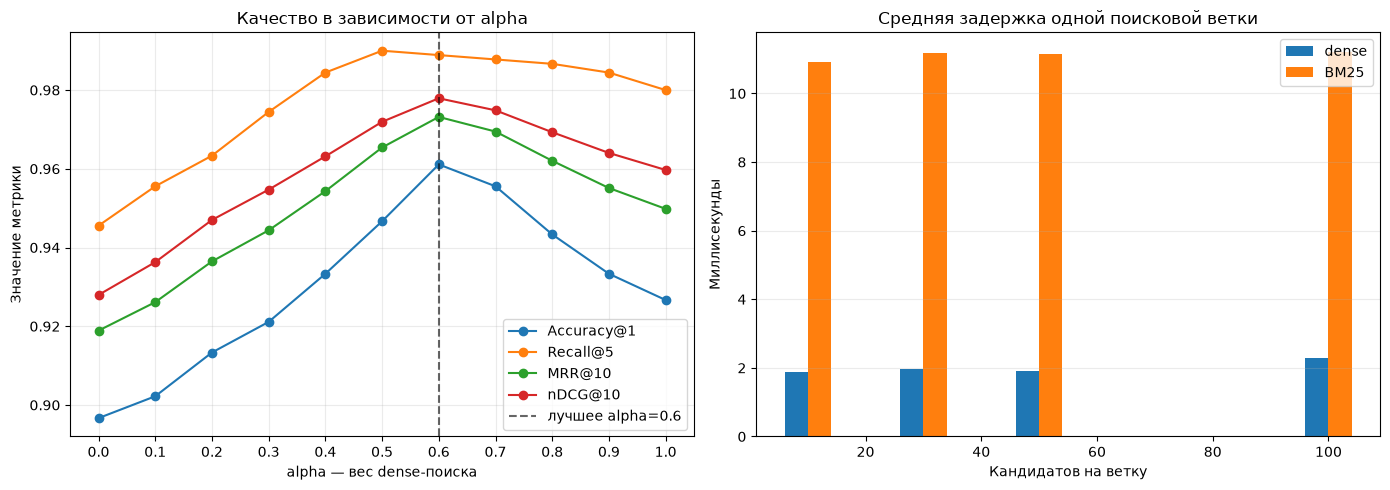

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric in ["Accuracy@1", "Recall@5", "MRR@10", "nDCG@10"]:
    axes[0].plot(alpha_table["alpha"], alpha_table[metric], marker="o", label=metric)
axes[0].axvline(best_alpha, color="black", linestyle="--", alpha=0.6, label=f"лучшее alpha={best_alpha:.1f}")
axes[0].set_title("Качество в зависимости от alpha")
axes[0].set_xlabel("alpha — вес dense-поиска")
axes[0].set_ylabel("Значение метрики")
axes[0].set_xticks(alpha_table["alpha"])
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].bar(latency_table["кандидатов на ветку"] - 2, latency_table["dense, мс"], width=4, label="dense")
axes[1].bar(latency_table["кандидатов на ветку"] + 2, latency_table["BM25, мс"], width=4, label="BM25")
axes[1].set_title("Средняя задержка одной поисковой ветки")
axes[1].set_xlabel("Кандидатов на ветку")
axes[1].set_ylabel("Миллисекунды")
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

## 11. Пример выдачи

Покажем несколько результатов для первого вопроса при лучшем значении `alpha`. Правильный документ отмечен в отдельном столбце.

In [12]:
example_query_id = 0
example_ranking = rankings_by_alpha[best_alpha][example_query_id][:5]

example_table = pd.DataFrame(
    [
        {
            "место": rank,
            "document_id": document_id,
            "гибридный скор": score,
            "релевантный": document_id == example_query_id,
            "текст": documents[document_id][:350],
        }
        for rank, (document_id, score) in enumerate(example_ranking, start=1)
    ]
)

print("Вопрос:", queries[example_query_id])
display(example_table.style.format({"гибридный скор": "{:.4f}"}))

Вопрос: Какое содержание селена в морской воде?


,место,document_id,гибридный скор,релевантный,текст
0,1,0,1.0000,True,"Содержание селена в земной коре — около 500 мг/т. Основные черты геохимии селена в земной коре определяются близостью его ионного радиуса к ионному радиусу серы. Селен образует 37 минералов, среди которых в первую очередь должны быть отмечены ашавалит FeSe, клаусталит PbSe, тиманнит HgSe, гуанахуатит Bi2(Se, S)3, хастит CoSe2, платинит PbBi2(S, Se)"
1,2,75,0.2704,False,"Селен в организме взаимодействует с витаминами, ферментами и биологическими мембранами, участвует в регуляции обмена веществ, в обмене жиров, белков и углеводов, а также в окислительно-восстановительных процессах. Селен является составным компонентом более 30 жизненно важных биологически активных соединений организма. Селен входит в активный центр"
2,3,524,0.2308,False,"Верхний, палисадный слой плотно упакованных, вертикально-расположенных клеток прямо под верхним слоем эпидермиса; толщиной в одну или две клетки. Клетки этого слоя содержат гораздо больше хлоропластов, чем в нижележащем губчатом слое. Длинные клетки цилиндрической формы, как правило, уложены в один — пять слоёв. Они, находясь близко к границе листа"
3,4,89,0.1837,False,"Согласно этой гипотезе, организмы могли бы поглощать газообразный водород и питаться молекулами ацетилена, при этом в процессе их жизнедеятельности образовывался бы метан. В итоге на Титане наблюдалась бы нехватка ацетилена и снижение содержания водорода около поверхности. Измерения в инфракрасном диапазоне, выполненные спектрометром Кассини , не в"
4,5,893,0.1729,False,"Созревание начинается с того, что плод прекращает рост, разлагаются хлорофилл и дубильные вещества, в вакуолях накапливаются пигменты, определяющие характерную для данного вида окраску плодов. У некоторых видов растений, например картофеля, плоды даже при созревании остаются зелёными. В стенках плода сосредотачиваются различные пластические и энерг"


## 12. Итоги

- Локально развёрнута коллекция Qdrant с двумя именованными векторами для каждого документа.
- Dense-ветка ищет по смыслу с помощью дообученной E5-модели.
- Sparse-ветка ищет точные слова с помощью BM25.
- Перед смешиванием скоры каждой ветки нормализуются, иначе численно более крупная шкала подавляла бы вторую ветку.
- Размер пула кандидатов выбран по измеренному компромиссу качества и скорости.
- Качество проверено для всех `alpha` с шагом 0.1; конкретное лучшее значение напечатано выше и определяется экспериментом, а не выбирается заранее.

Важно: полученное оптимальное `alpha` относится именно к SberQuAD, этой модели и текущей схеме BM25. На другом языке, домене или наборе документов параметр нужно измерять заново.